# Определение жанра фильмов по текстовому описанию

### Постановка задачи

По текстовому описанию фильма провести его классификацию по жанрам

In [2]:
# Импорт библиотек

import re
import numpy as np
import pandas as pd

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence

from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer

# Метрики, по которым далее будем сравнивать модели
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

import warnings
warnings.filterwarnings("ignore")

In [6]:
torch.manual_seed(42)
np.random.seed(42)

In [7]:
data_path = 'https://code.s3.yandex.net/datasets/ds_s26_t5_train_data.csv'


In [8]:

def train_epoch(model, loader, optimizer, criterion):
    """Обучение модели за одну эпоху"""

    # Переводим модель в режим обучения.
    # В этом режиме корректно работают Dropout, 
	# BatchNorm и другие обучаемые слои.
    model.train()

    losses = []
    preds_all = []
    targets_all = []

    # Проходим по всем батчам обучающей выборки
    for x, y in loader:
        # Обнуляем накопленные градиенты
        optimizer.zero_grad()

        # Получаем предсказания модели
        logits = model(x)

        # Считаем функцию потерь
        loss = criterion(logits, y)

        # Вычисляем градиенты
        loss.backward()

        # Ограничиваем слишком большие значения градиентов.
        # Это делает обучение более стабильным.
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)

        # Обновляем веса модели
        optimizer.step()

        # Сохраняем статистику для расчёта итоговых метрик
        losses.append(loss.item())

        preds_all.extend(logits.argmax(1).numpy())
        targets_all.extend(y.numpy())

    # После окончания эпохи вычисляем accuracy
    acc = accuracy_score(targets_all, preds_all)

    # Возвращаем средний loss и accuracy
    return float(np.mean(losses)), acc


In [17]:
# Функция оценки модели
def evaluate(model, loader, criterion):

    # Переключаем модель в режим оценки.
    # Dropout отключается, 
# BatchNorm использует накопленную статистику.
    model.eval()

    losses = []
    preds_all = []
    targets_all = []

    # Во время оценки градиенты не нужны.
    # Это уменьшает потребление памяти и ускоряет вычисления.
    with torch.no_grad():

        for x, y in loader:
            logits = model(x)

            losses.append(criterion(logits, y).item())

            preds_all.extend(logits.argmax(1).numpy())
            targets_all.extend(y.numpy())

    # Возвращаем сразу несколько метрик.
    # Они понадобятся для объективного сравнения разных моделей.
    return {
        "loss": float(np.mean(losses)),
        "accuracy": accuracy_score(targets_all, preds_all),
        "precision": precision_score(
            targets_all,
            preds_all,
            average="macro",
            zero_division=0
        ),
        "recall": recall_score(
            targets_all,
            preds_all,
            average="macro",
            zero_division=0
        ),
        "f1": f1_score(
            targets_all,
            preds_all,
            average="macro",
            zero_division=0
        ),
    }

In [9]:
# Загрузка датасета
df = pd.read_csv(data_path)

print(f"Всего примеров: {len(df)}")

# Посмотрим, сколько объектов относится к каждому жанру
print(df["genre"].value_counts())

print(df.head(3))


Всего примеров: 3300
genre
drama          1315
documentary    1253
comedy          732
Name: count, dtype: int64
   Unnamed: 0  id                         title  genre  \
0           0   1  Oscar et la dame rose (2009)  drama   
1           1   4         The Secret Sin (1915)  drama   
2           2   5        The Unrecovered (2007)  drama   

                                         description  label  
0  Listening in to a conversation between his doc...      2  
1  To help their unemployed father make ends meet...      2  
2  The film's title refers not only to the un-rec...      2  


In [10]:
# Преобразование текстовых жанров в числовые метки
encoder = LabelEncoder()

# Нейронные сети работают только с числами,
# поэтому каждому жанру присваивается уникальный номер.
df["label"] = encoder.fit_transform(df["genre"])

num_classes = len(encoder.classes_)

print("Классы:", encoder.classes_)

Классы: ['comedy' 'documentary' 'drama']


In [11]:
# Деление данных на обучающую и тестовую выборки
train_df, test_df = train_test_split(
    df,
    test_size=0.2,

    # Сохраняем одинаковые пропорции жанров
    # в обучающей и тестовой выборках.
    stratify=df["label"],

    random_state=42
)
print(f"Train length: {train_df.shape[0]}, Test length: {test_df.shape[0]}")

Train length: 2640, Test length: 660


### 1. Обучение Многослойного перцептрона (MLP)

- Обучение стандартного многослойного перцептрона на трёх класса

In [12]:
# TF-IDF признаки — объявляем векторизатор 
# с необходимыми параметрами

tfidf = TfidfVectorizer(max_features=10000, stop_words="english", 
ngram_range=(1, 2))

# Векторизуем выборки
X_train_tfidf = tfidf.fit_transform(train_df["description"])
X_test_tfidf  = tfidf.transform(test_df["description"])

# Получаем лейблы для обучения и теста
y_train = train_df["label"].values
y_test  = test_df["label"].values

print(f"TF-IDF shape: {X_train_tfidf.shape}")


TF-IDF shape: (2640, 10000)


In [13]:
# Объявляем класс датасета для загрузки данных
class TfidfDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.FloatTensor(X.toarray())
        self.y = torch.LongTensor(y)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


In [14]:

# Формируем DataLoader для обеих выборок
train_loader_mlp = DataLoader(TfidfDataset(X_train_tfidf, y_train), 
batch_size=256, shuffle=True)
test_loader_mlp  = DataLoader(TfidfDataset(X_test_tfidf, y_test), 
batch_size=256)


In [15]:
# Определяем класс модели
class MLPClassifier(nn.Module):
    def __init__(self, input_dim: int, num_classes: int, dropout: float = 0.3):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.BatchNorm1d(512),         
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(dropout / 2),

            nn.Linear(128, num_classes)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


In [16]:

# Создаём экземпляр модели
mlp = MLPClassifier(X_train_tfidf.shape[1], num_classes)
print(f"MLP параметров: {sum(p.numel() for p in mlp.parameters()):,}")

# Объявляем количество эпох
EPOCHS = 10

# Объявляем необходимые для работы оптимизаторы, 
# функцию потерь и шедулер
optimizer_mlp = torch.optim.Adam(mlp.parameters(), 
lr=1e-3, weight_decay=1e-4)
scheduler_mlp = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_mlp, T_max=EPOCHS)
criterion = nn.CrossEntropyLoss()

# Словарь для сохранения метрик
history_mlp = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}



MLP параметров: 5,286,659


In [18]:
# Производим обучение по эпохам
for epoch in range(EPOCHS):
	# Получаем метрики
    train_loss, train_acc = train_epoch(mlp, train_loader_mlp, optimizer_mlp, criterion)
    metrics = evaluate(mlp, test_loader_mlp, criterion)
    scheduler_mlp.step()

    history_mlp["train_loss"].append(train_loss)
    history_mlp["val_loss"].append(metrics["loss"])
    history_mlp["train_acc"].append(train_acc)
    history_mlp["val_acc"].append(metrics["accuracy"])

    print(f"Epoch {epoch+1:2d}/{EPOCHS} | "
              f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
              f"val_loss={metrics['loss']:.4f} val_acc={metrics['accuracy']:.4f} "
              f"f1={metrics['f1']:.4f}")

Epoch  1/10 | train_loss=0.9201 train_acc=0.5727 | val_loss=1.0747 val_acc=0.5288 f1=0.3797
Epoch  2/10 | train_loss=0.3298 train_acc=0.9133 | val_loss=1.0444 val_acc=0.4515 f1=0.3181
Epoch  3/10 | train_loss=0.0293 train_acc=0.9966 | val_loss=0.9613 val_acc=0.5197 f1=0.4565
Epoch  4/10 | train_loss=0.0041 train_acc=0.9996 | val_loss=0.7832 val_acc=0.6318 f1=0.6260
Epoch  5/10 | train_loss=0.0009 train_acc=1.0000 | val_loss=0.6962 val_acc=0.6894 f1=0.6794
Epoch  6/10 | train_loss=0.0015 train_acc=0.9996 | val_loss=0.7358 val_acc=0.6985 f1=0.6827
Epoch  7/10 | train_loss=0.0005 train_acc=1.0000 | val_loss=0.8608 val_acc=0.7091 f1=0.6902
Epoch  8/10 | train_loss=0.0005 train_acc=1.0000 | val_loss=0.9898 val_acc=0.7136 f1=0.6933
Epoch  9/10 | train_loss=0.0007 train_acc=1.0000 | val_loss=1.0583 val_acc=0.7167 f1=0.6961
Epoch 10/10 | train_loss=0.0004 train_acc=1.0000 | val_loss=1.0858 val_acc=0.7197 f1=0.6984


### 2. Обучение Многослойного перцептрона (MLP)

- обучение многослойного перцептрона, но с добавлением слоёв специально для создания текстовой модели.

In [19]:
# Функция токенизации текста
def tokenize(text: str):
    # Переводим текст в нижний регистр 
	# и разбиваем его на отдельные слова.
    # В качестве токенов используются последовательности букв и цифр.
    return re.findall(r"\b\w+\b", text.lower())



In [20]:
# Индекс токена дополнения (padding).
# Используется для выравнивания предложений внутри батча.
PAD_IDX = 0

# Индекс для всех неизвестных слов,
# которые отсутствовали в обучающей выборке.
UNK_IDX = 1

# Построение словаря
# Словарь строится ТОЛЬКО по обучающей выборке.
# Это предотвращает утечку информации из тестовой выборки.
counter = Counter()

for text in train_df["description"]:
    counter.update(tokenize(text))

# Берём только 30 000 самых частых слов.
# Остальные слова будут заменяться токеном UNK.
vocab = {
    word: idx + 2      # +2, так как индексы 0 и 1 
# уже заняты PAD и UNK
    for idx, (word, _) in enumerate(counter.most_common(30000))
}

print(f"Размер словаря: {len(vocab) + 2}")



Размер словаря: 25287


In [21]:
# Определяем Dataset
class TextDataset(Dataset):

    def __init__(self, texts, labels):

        # Сохраняем тексты и соответствующие им метки классов
        self.texts = texts.tolist()
        self.labels = labels.tolist()

    def __len__(self):
        # Количество объектов в датасете
        return len(self.labels)

    def __getitem__(self, idx):

        # Получаем текст
        tokens = tokenize(self.texts[idx])

        # Каждое слово заменяем его индексом из словаря.
        # Если слово отсутствует, используем индекс UNK.
        encoded = [vocab.get(t, UNK_IDX) for t in tokens]

        # Возвращаем последовательность индексов 
		# и правильную метку класса
        return torch.LongTensor(encoded), self.labels[idx]



In [22]:
# Функция формирования батча
def collate_fn(batch):

    # Извлекаем последовательности слов
    sequences = [item[0] for item in batch]

    # Извлекаем соответствующие им классы
    labels = [item[1] for item in batch]

    # Предложения имеют разную длину.
    # pad_sequence дополняет более короткие предложения
    # специальным токеном PAD_IDX до длины 
	# самого длинного предложения.
    padded = pad_sequence(
        sequences,
        batch_first=True,
        padding_value=PAD_IDX
    )

    return padded, torch.LongTensor(labels)


In [23]:

# объявляем DataLoader, который автоматически формирует батчи,
# перемешивает обучающие данные
# и вызывает collate_fn для добавления паддингов.
train_loader_text = DataLoader(
    TextDataset(train_df["description"], train_df["label"]),
    batch_size=64,
    shuffle=True,
    collate_fn=collate_fn
)

test_loader_text = DataLoader(
    TextDataset(test_df["description"], test_df["label"]),
    batch_size=64,
    collate_fn=collate_fn
)



In [24]:
# Архитектура модели
class TextMLPClassifier(nn.Module):
    def __init__(
        self,
        vocab_size: int,
        embedding_dim: int,
        hidden_dim: int,
        num_classes: int,
        padding_idx: int = 0,
        dropout: float = 0.4,
    ):
        super().__init__()

        self.padding_idx = padding_idx

        # Слой эмбеддингов
        # Каждому слову словаря сопоставляется обучаемый вектор
        # размерности embedding_dim.
        #
        # padding_idx говорит модели,
        # что эмбеддинг PAD обучать не нужно.
        #
        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=padding_idx
        )

        # После pooling объединяются два вектора:
        # Mean Pooling и Max Pooling.
        # Поэтому итоговая размерность увеличивается вдвое.
        pooled_dim = embedding_dim * 2

        # MLP-классификатор
        # На вход получает один вектор,
        # описывающий всё предложение.
        self.mlp = nn.Sequential(

            nn.Linear(pooled_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.BatchNorm1d(hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout / 2),

            nn.Linear(hidden_dim // 2, hidden_dim // 4),
            nn.ReLU(),
            nn.Dropout(dropout / 4),

            # Финальный слой выдаёт логиты
            # для каждого класса
            nn.Linear(hidden_dim // 4, num_classes),
        )

    def forward(self, input_ids):

        # input_ids имеет форму:
        # [batch_size, sequence_length]

        # Получаем эмбеддинги слов
        # [B, L] -> [B, L, E]
        emb = self.embedding(input_ids)

        # Создаём маску.
        # True означает настоящее слово,
        # False — токен PAD.
        mask = (input_ids != self.padding_idx)
        # Mean Pooling
        # Усредняем эмбеддинги только настоящих слов.
        # PAD-токены в вычислении не участвуют.
        mask_f = mask.unsqueeze(-1).float()

        lengths = mask_f.sum(dim=1).clamp(min=1)

        mean_pooled = (
            emb * mask_f
        ).sum(dim=1) / lengths

        # Max Pooling
        # Перед поиском максимума PAD заменяется на -inf,
        # чтобы он никогда не оказался максимальным значением.
        emb_masked = emb.masked_fill(
            ~mask.unsqueeze(-1),
            float("-inf")
        )

        max_pooled = emb_masked.max(dim=1).values

        # Объединяем два представления предложения
        # Mean pooling хранит общую информацию,
        # а Max pooling позволяет выделить наиболее
        # важные признаки предложения.
        pooled = torch.cat(
            [mean_pooled, max_pooled],
            dim=1
        )

        # Передаём итоговый вектор
        # в полносвязную сеть.
        return self.mlp(pooled)


In [25]:
EPOCHS = 10

# Объявление модели
text_model = TextMLPClassifier(
    vocab_size=len(vocab) + 2,
    embedding_dim=128,
    hidden_dim=512,
    num_classes=num_classes,
    padding_idx=PAD_IDX,
    dropout=0.4,
)

# Посмотрим, сколько обучаемых параметров содержит модель.
print(
    f"TextMLP параметров: "
    f"{sum(p.numel() for p in text_model.parameters()):,}"
)


TextMLP параметров: 3,534,467


In [26]:
# Настройка обучения
# Оптимизатор Adam
optimizer_text = torch.optim.Adam(
    text_model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

# Планировщик постепенно уменьшает learning rate,
# что помогает модели аккуратнее сходиться к минимуму.
scheduler_text = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer_text,
    T_max=EPOCHS
)

# Функция потерь для многоклассовой классификации
criterion = nn.CrossEntropyLoss()

# История обучения.
history_text = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}


In [27]:

# Цикл обучения
for epoch in range(EPOCHS):
    train_loss, train_acc = train_epoch(
        text_model,
        train_loader_text,
        optimizer_text,
        criterion
    )

    # Проверяем качество модели
    # на тестовой выборке
    metrics = evaluate(
        text_model,
        test_loader_text,
        criterion
    )

    # Обновляем learning rate
    scheduler_text.step()

    # Сохраняем статистику
    history_text["train_loss"].append(train_loss)
    history_text["val_loss"].append(metrics["loss"])

    history_text["train_acc"].append(train_acc)
    history_text["val_acc"].append(metrics["accuracy"])

    # Выводим результаты текущей эпохи
    print(
        f"Epoch {epoch + 1:2d}/{EPOCHS} | "
        f"train_loss={train_loss:.4f} "
        f"train_acc={train_acc:.4f} | "
        f"val_loss={metrics['loss']:.4f} "
        f"val_acc={metrics['accuracy']:.4f} "
        f"f1={metrics['f1']:.4f}"
    )

Epoch  1/10 | train_loss=0.9769 train_acc=0.5307 | val_loss=1.2157 val_acc=0.4848 f1=0.3393
Epoch  2/10 | train_loss=0.7756 train_acc=0.6595 | val_loss=0.9537 val_acc=0.5773 f1=0.5195
Epoch  3/10 | train_loss=0.6334 train_acc=0.7318 | val_loss=0.8893 val_acc=0.6030 f1=0.5815
Epoch  4/10 | train_loss=0.5331 train_acc=0.7773 | val_loss=0.9140 val_acc=0.6258 f1=0.5495
Epoch  5/10 | train_loss=0.4393 train_acc=0.8212 | val_loss=1.4425 val_acc=0.5803 f1=0.5117
Epoch  6/10 | train_loss=0.3658 train_acc=0.8576 | val_loss=1.2019 val_acc=0.6348 f1=0.5191
Epoch  7/10 | train_loss=0.2985 train_acc=0.8894 | val_loss=1.0007 val_acc=0.6273 f1=0.6052
Epoch  8/10 | train_loss=0.2458 train_acc=0.9129 | val_loss=1.0714 val_acc=0.6106 f1=0.5876
Epoch  9/10 | train_loss=0.2429 train_acc=0.9110 | val_loss=1.0860 val_acc=0.6152 f1=0.5829
Epoch 10/10 | train_loss=0.2234 train_acc=0.9155 | val_loss=1.1021 val_acc=0.6288 f1=0.5977


### Результаты обучения

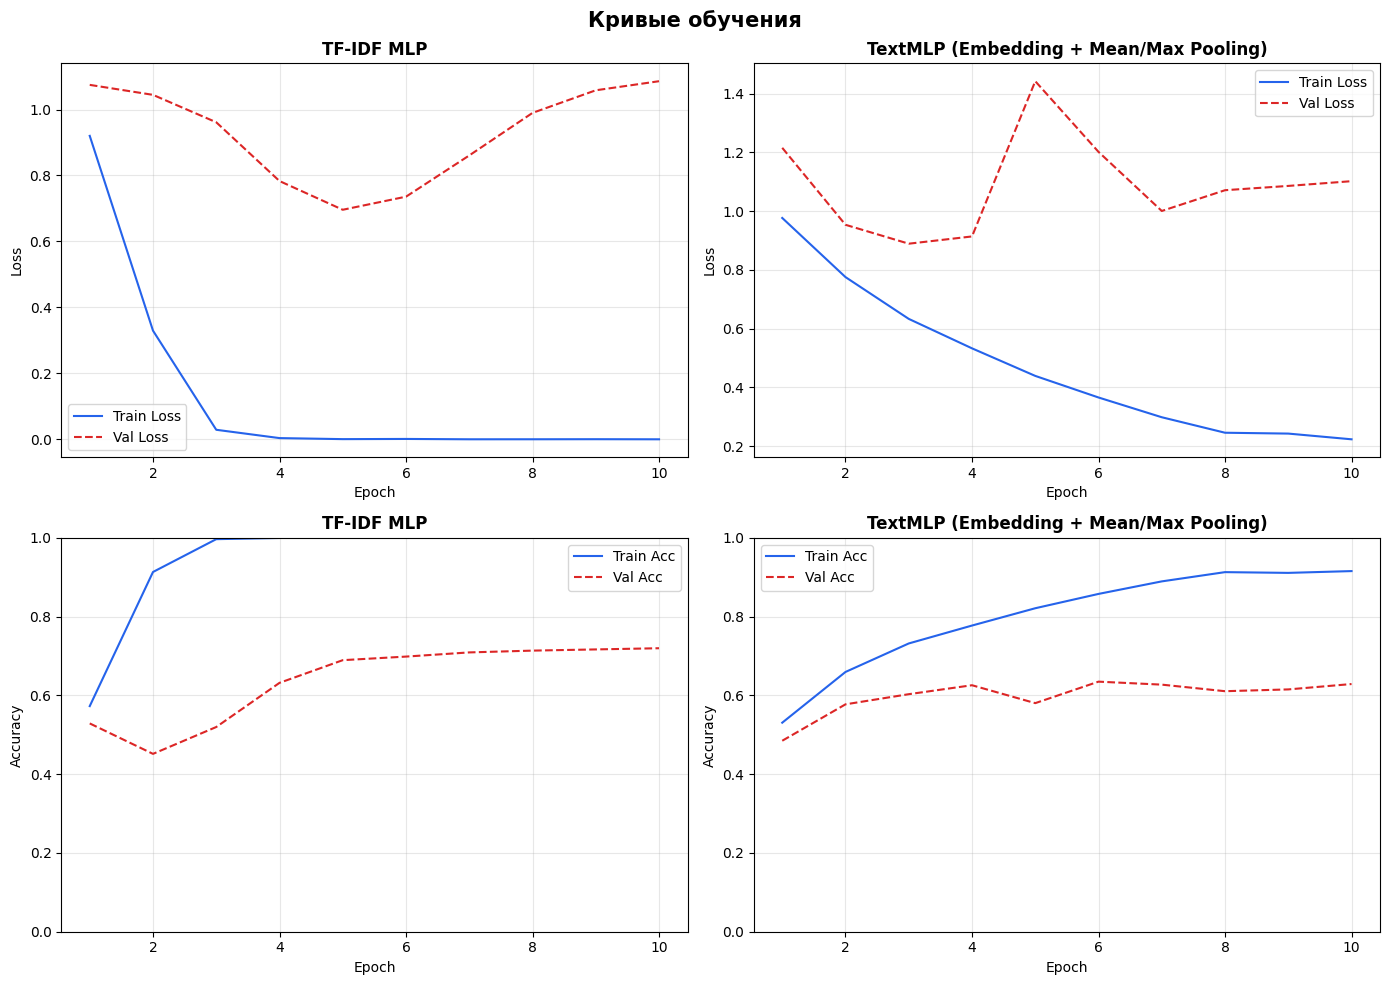

In [28]:
# Создаём фигуру размером 2×2.
# На ней будут расположены графики функций потерь и accuracy
# для двух обученных моделей.
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Добавляем общий заголовок для всей фигуры
fig.suptitle("Кривые обучения", fontsize=15, fontweight="bold")

# Номера эпох по оси X
epochs_range = range(1, EPOCHS + 1)


# Графики функции потерь (Loss)
# Строим сразу два графика:
# слева — TF-IDF + MLP,
# справа — TextMLP с Embedding.
for ax, hist, title in zip(
    [axes[0, 0], axes[0, 1]],
    [history_mlp, history_text],
    ["TF-IDF MLP", "TextMLP (Embedding + Mean/Max Pooling)"]
):

    # Ошибка на обучающей выборке
    ax.plot(
        epochs_range,
        hist["train_loss"],
        label="Train Loss",
        color="#2563EB"
    )

    # Ошибка на тестовой (валидационной) выборке
    ax.plot(
        epochs_range,
        hist["val_loss"],
        label="Val Loss",
        color="#DC2626",
        linestyle="--"
    )

    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")

    # Добавляем легенду и сетку
    ax.legend()
    ax.grid(alpha=0.3)


# Графики Accuracy
# Аналогично строим графики точности
# для обеих моделей.
for ax, hist, title in zip(
    [axes[1, 0], axes[1, 1]],
    [history_mlp, history_text],
    ["TF-IDF MLP", "TextMLP (Embedding + Mean/Max Pooling)"]
):

    # Accuracy на обучающей выборке
    ax.plot(
        epochs_range,
        hist["train_acc"],
        label="Train Acc",
        color="#2563EB"
    )

    # Accuracy на тестовой выборке
    ax.plot(
        epochs_range,
        hist["val_acc"],
        label="Val Acc",
        color="#DC2626",
        linestyle="--"
    )

    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy")

    # Accuracy всегда находится в диапазоне от 0 до 1,
    # поэтому фиксируем масштаб оси Y.
    ax.set_ylim(0, 1)

    ax.legend()
    ax.grid(alpha=0.3)


# Автоматически подбираем расстояния между графиками,
# чтобы подписи не перекрывались.
plt.tight_layout()

# Отображаем итоговую фигуру.
plt.show()

In [29]:
mlp_metrics  = evaluate(mlp, test_loader_mlp, criterion) 
# Считаем метрики для mlp модели
text_metrics = evaluate(text_model, test_loader_text, criterion) 
# Считаем метрики для текстовой модели

results_df = pd.DataFrame([
    {"Модель": "TF-IDF + MLP",                **mlp_metrics},
    {"Модель": "Embedding + MLP (Mean+Max)",  **text_metrics},
]).set_index("Модель") # Формируем датафрейм из метрик

# Оформляем колонки
results_df = results_df[["accuracy", "precision", "recall", "f1", "loss"]]
results_df.columns = ["Accuracy", "Precision", 
"Recall", "F1", "Val Loss"]

print(results_df.round(4))

                            Accuracy  Precision  Recall      F1  Val Loss
Модель                                                                   
TF-IDF + MLP                  0.7197     0.6983  0.6999  0.6984    1.0858
Embedding + MLP (Mean+Max)    0.6288     0.5994  0.5973  0.5977    1.1021
